# Нефть и рубль: насколько устойчива связь?

Авторы исходной работы: Бойко София и Шумакова Екатерина.

**Вопрос:** добавляет ли Brent информацию об изменении отношения рыночного курса к ППС сверх собственной инерции курса?

Ноутбук выполняет те же функции, что и `main.py`, на сохранённом снимке без сети. Результаты не являются причинной оценкой или готовым прогнозом.

In [1]:
from pathlib import Path
import sys
import io
from contextlib import redirect_stdout
from IPython.display import display, Image

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "config.toml").exists() and (p / "main.py").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from main import run_pipeline
with redirect_stdout(io.StringIO()):
    result = run_pipeline(ROOT, output_dir=ROOT / "build" / "notebook", pdf=False)
df, tables = result["data"], result["tables"]
output = result["output_dir"]
print(f"Полные годы: {df.year.min()}-{df.year.max()}, N={len(df)}")

Полные годы: 1993-2025, N=33


## 1. Источники и контроль качества

Brent: FRED DCOILBRENTEU; курс: FRED CCUSMA02RUM618N/OECD; ППС: World Bank PA.NUS.PRVT.PP.

`q = E / PPP`. Рост q интерпретируется как относительное ослабление рубля. ППС - статистическая оценка потребления в RUB за международный доллар; это не торгуемый курс.

Год должен содержать 12 месяцев курса, 12 месяцев Brent и не менее 200 дневных цен. Порог не гарантирует присутствия каждого торгового дня. Разности не могут перескакивать пропущенные годы.

In [2]:
coverage = result["coverage"]
display(coverage.loc[~coverage.included,
    ["year", "nominal_usd_rub_months", "brent_observations", "exclusion_reason"]])
display(df[["year", "brent", "nominal_usd_rub", "ppp_basket_usd_rub", "basket_real_usd_rub"]].head())

,year,nominal_usd_rub_months,brent_observations,exclusion_reason
0,1992,7,257,incomplete_fx


,year,brent,nominal_usd_rub,ppp_basket_usd_rub,basket_real_usd_rub
0,1993,17.013413,0.973209,0.171460,5.676000
1,1994,15.856389,2.204073,0.681318,3.235015
2,1995,17.015850,4.560500,1.971040,2.313753
3,1996,20.639803,5.125472,2.845415,1.801309
4,1997,19.108508,5.783538,3.276927,1.764927


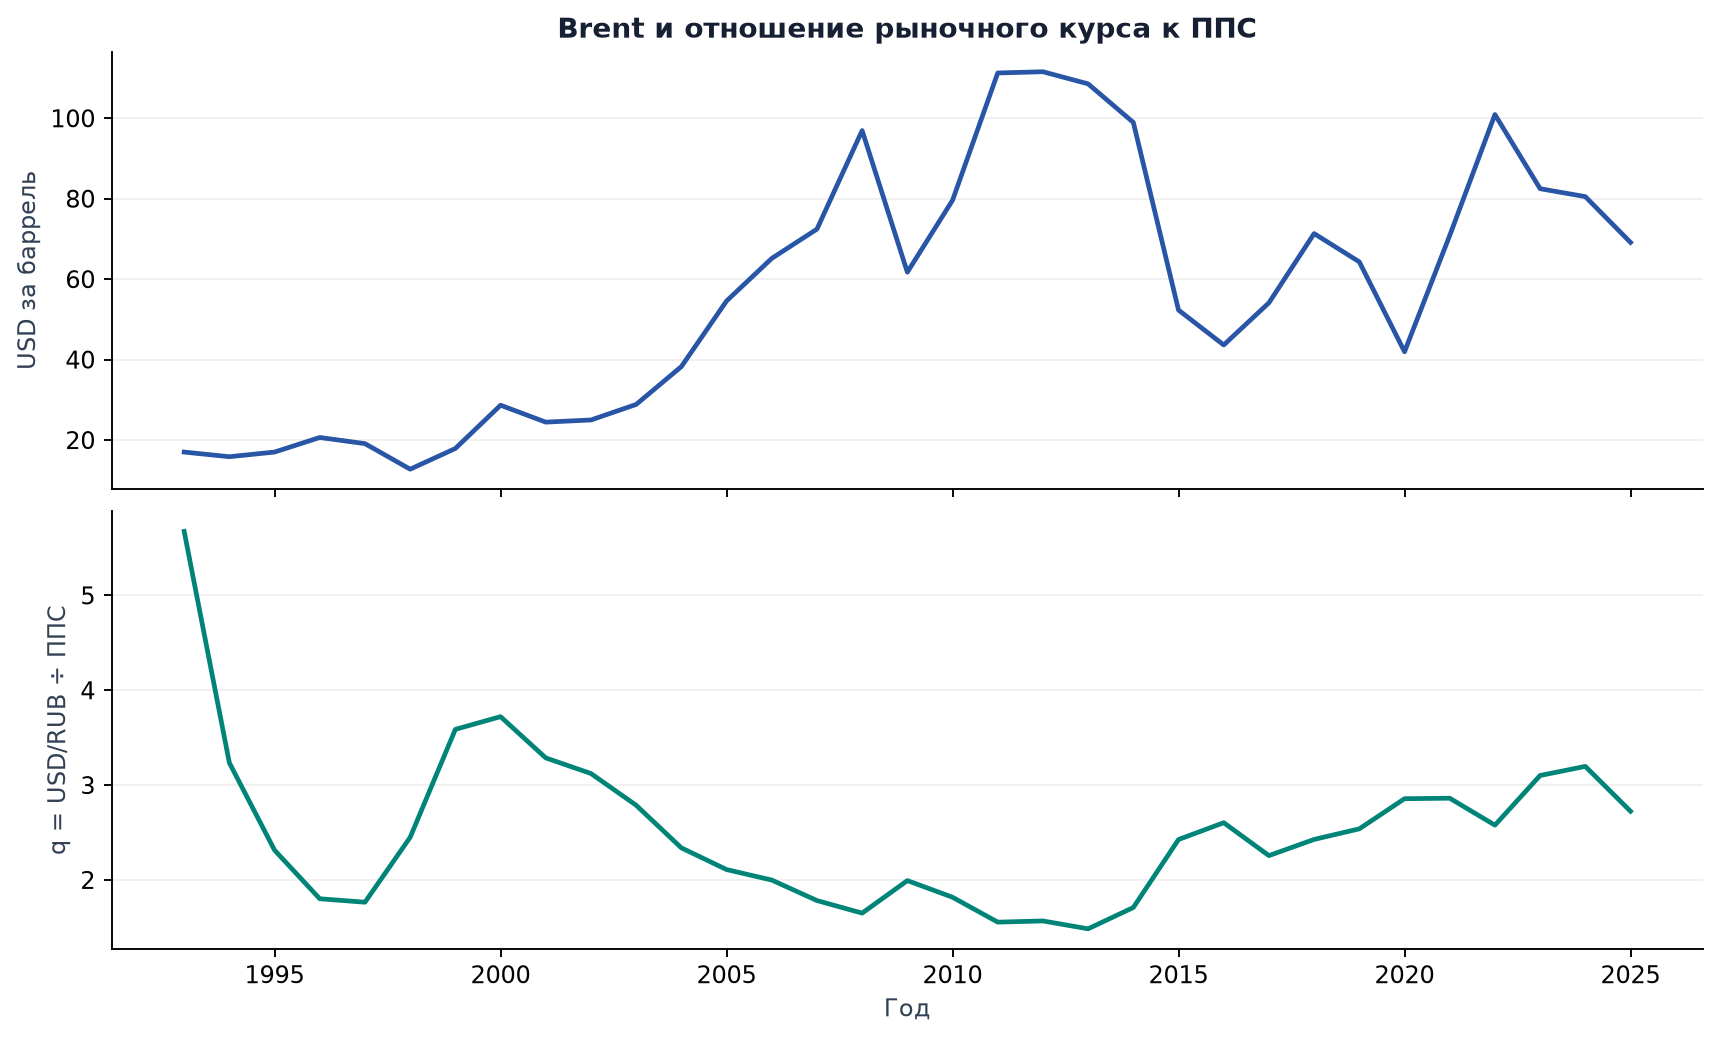

In [3]:
display(Image(filename=str(output / "figures" / "overview.png")))

## 2. Добавочная связь Brent

Основная модель: Δlog(q_t) = α + φ Δlog(q_(t-1)) + β Δlog(Brent_t) + ε_t.

Сравниваем с AR(1) без нефти и ограниченным набором расширений. Все модели изменений используют одни и те же годы; модель уровней хранится отдельно. HAC-интервалы включают поправку малой выборки. Настройки заданы в config.toml.

In [4]:
comparison = tables["model_comparison"].set_index("model")
display(comparison[["n_obs", "start_year", "end_year", "adj_r_squared", "aic", "bic", "bg_f_p_value"]])
print("Добавление Brent к AR(1):")
print((comparison.loc["ar1_oil", ["aic", "bic"]] - comparison.loc["ar1", ["aic", "bic"]]).round(3))

,n_obs,start_year,end_year,adj_r_squared,aic,bic,bg_f_p_value
model,,,,,,,
ar1_oil,31,1995,2025,0.441106,-37.474860,-33.172898,0.512313
ar1_oil_crises,31,1995,2025,0.492945,-37.271073,-27.233162,0.362959
ar1_oil_lag,31,1995,2025,0.421059,-35.509805,-29.773857,0.529359
ar1,31,1995,2025,0.220313,-28.066136,-25.198161,0.454551
changes,31,1995,2025,0.205693,-27.490215,-24.622241,0.052135
changes_lag,31,1995,2025,0.210456,-26.764514,-22.462553,0.054015


Добавление Brent к AR(1):
aic   -9.409
bic   -7.975
dtype: float64


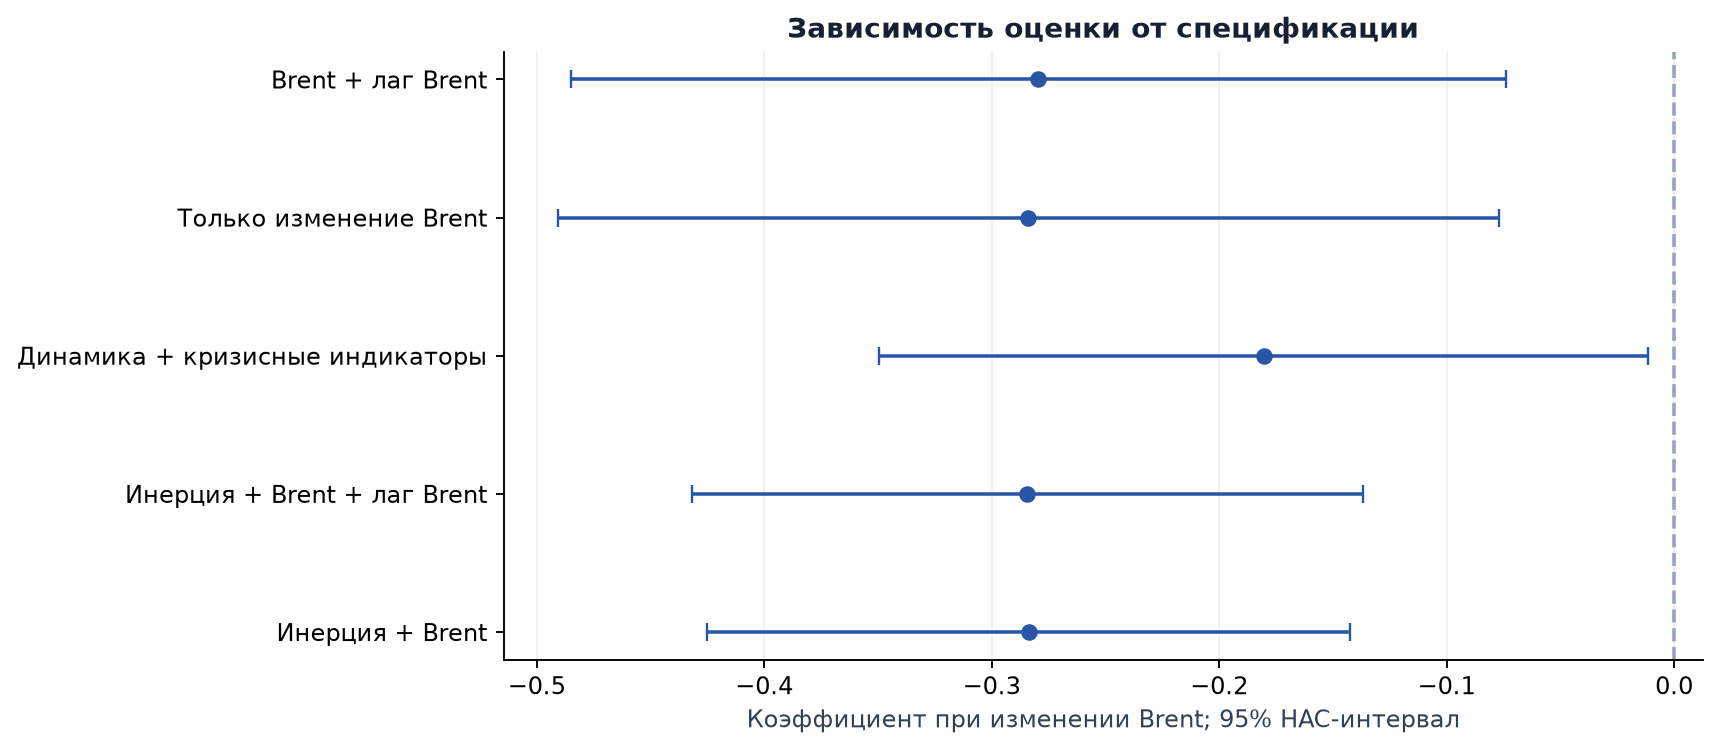

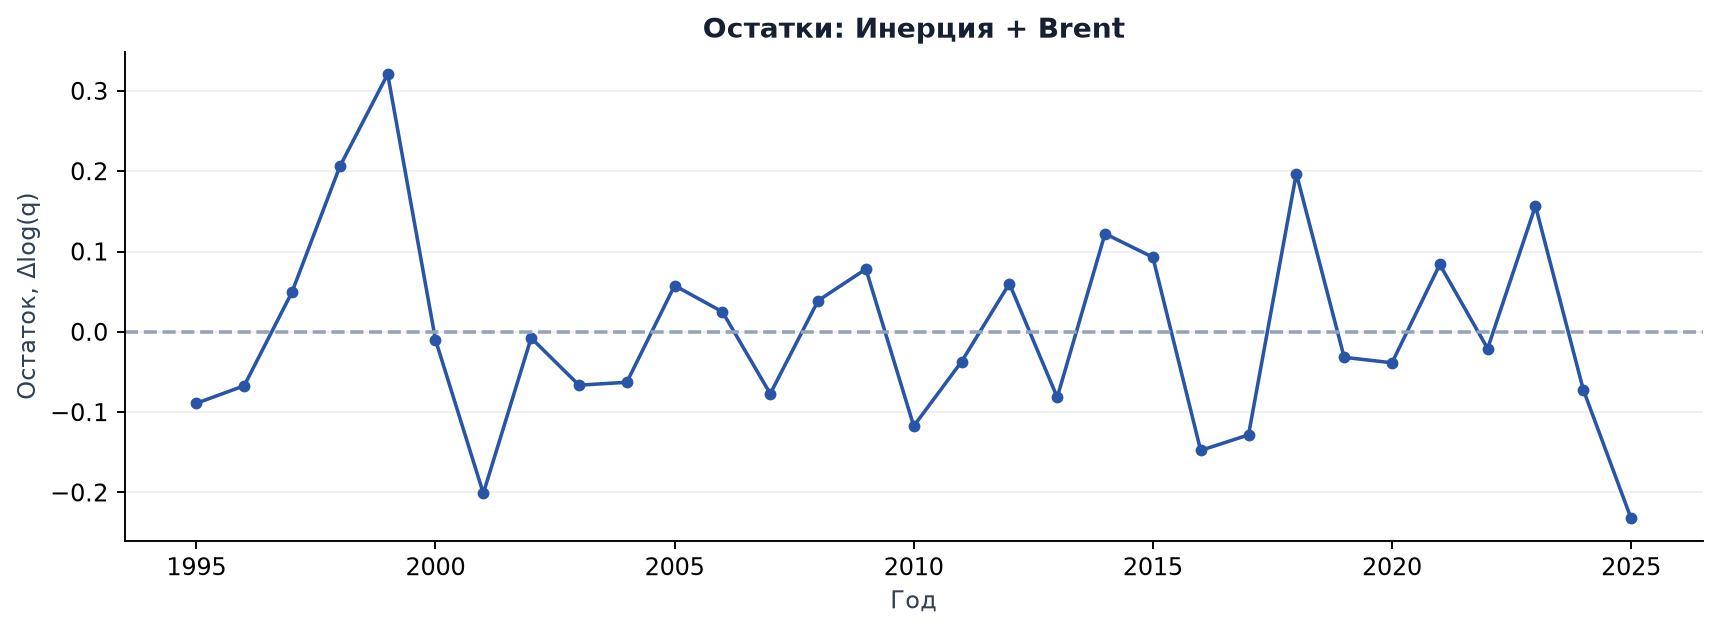

In [5]:
display(Image(filename=str(output / "figures" / "brent_coefficients.png")))
display(Image(filename=str(output / "figures" / "residuals.png")))

## 3. Стационарность и коинтеграция

ADF и KPSS имеют разные нулевые гипотезы. Неотклонение единичного корня не доказывает I(1).

В Engle-Granger сохраняются оба направления регрессии и 0/1/2 фиксированных лага. Основной порядок - log(q) на log(Brent) с одним лагом. Значимость нельзя выбирать перебором удобных настроек; предпосылка I(1) и малый размер выборки ограничивают интерпретацию.

In [6]:
display(tables["stationarity_tests"])
display(tables["cointegration_test"][["y0", "y1", "maxlag", "autolag", "primary", "coint_t", "p_value"]])

,variable,n_obs,trend,adf_stat,adf_p_value,adf_usedlag,adf_effective_n,adf_autolag,kpss_stat,kpss_p_value,kpss_p_bound,kpss_usedlag
0,log_brent,33,c,-1.542566,0.512359,2,30,None,0.674107,0.015899,,3
1,log_basket_real_usd_rub,33,c,-2.265963,0.183181,2,30,None,0.186696,0.100000,>=,3
2,dlog_brent,32,c,-3.229489,0.018340,2,29,None,0.200750,0.100000,>=,10
3,dlog_basket_real_usd_rub,32,c,-4.144615,0.000817,2,29,None,0.224252,0.100000,>=,1


,y0,y1,maxlag,autolag,primary,coint_t,p_value
0,log_basket_real_usd_rub,log_brent,0,None,False,-2.923288,0.129584
1,log_basket_real_usd_rub,log_brent,1,None,True,-3.568736,0.026769
2,log_basket_real_usd_rub,log_brent,2,None,False,-2.831139,0.155978
3,log_brent,log_basket_real_usd_rub,0,None,False,-1.254199,0.843131
4,log_brent,log_basket_real_usd_rub,1,None,False,-1.942623,0.558244
5,log_brent,log_basket_real_usd_rub,2,None,False,-1.601649,0.720194


## 4. Устойчивость и влияние отдельных лет

Начала выборки: 1993, 1995, 2000; разности и лаги пересчитываются внутри каждого периода. Проверяются также 0/1/2 лага HAC. Удаление одной строки из фиксированного регрессионного дизайна - диагностика влияния, не проверка прогноза. Наблюдения не удаляются из основной модели по результату этой диагностики.

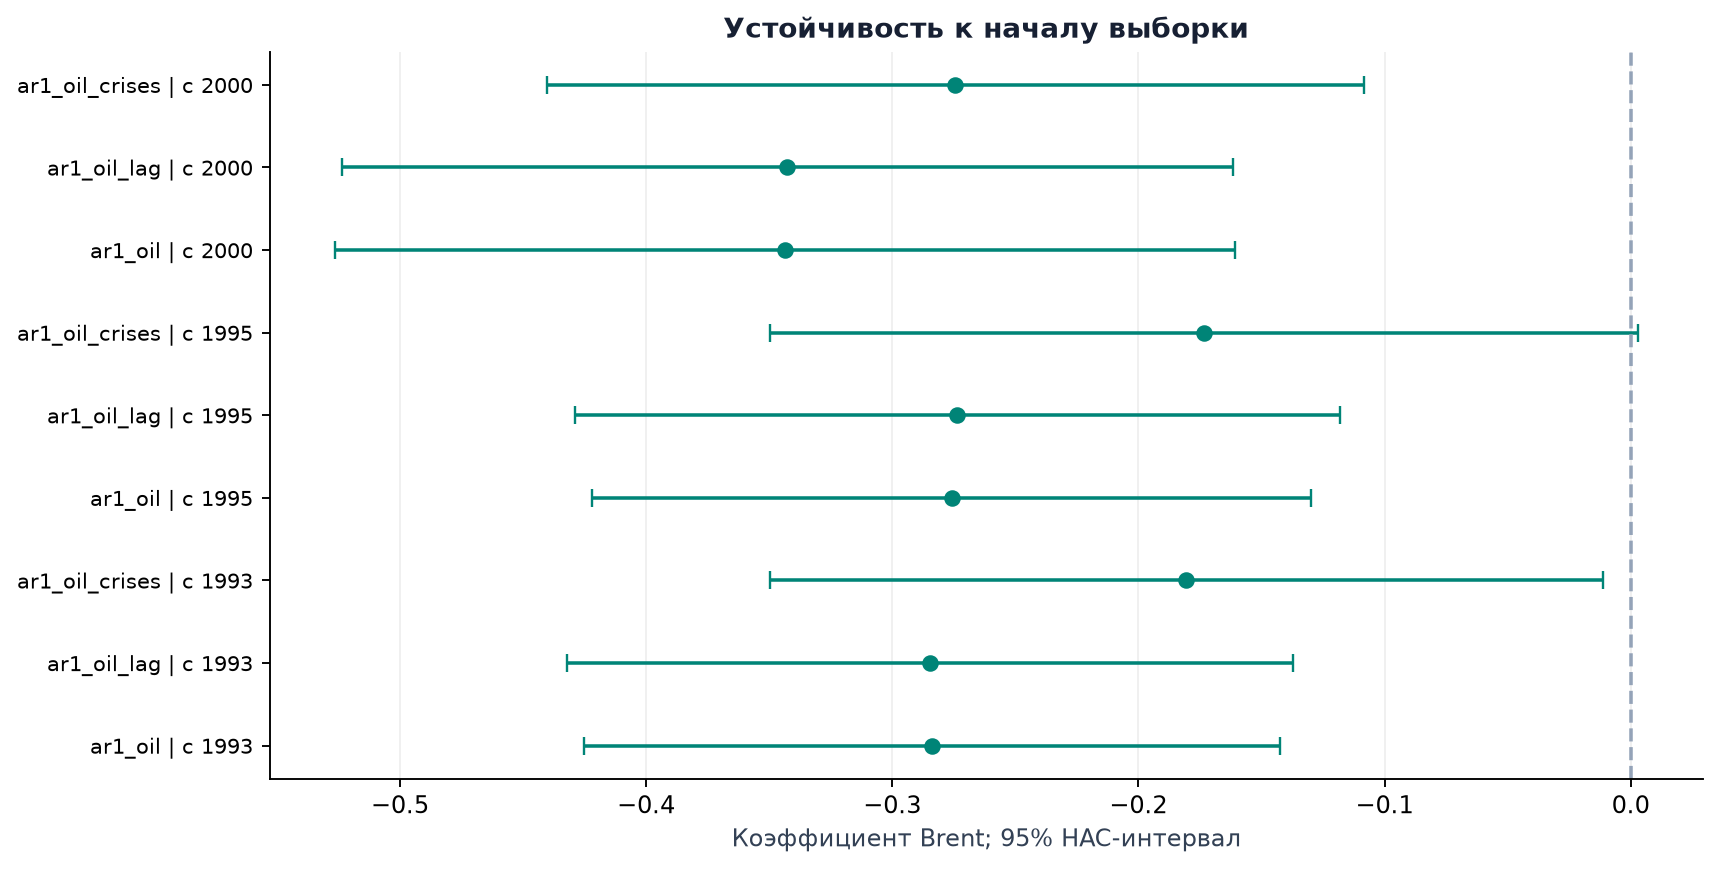

,start_year_requested,n_obs,hac_lags,coef,ci_low,ci_high,hac_p_value
0,1993,31,0,-0.283811,-0.449384,-0.118239,0.001531
3,1993,31,1,-0.283811,-0.425223,-0.142400,0.000312
6,1993,31,2,-0.283811,-0.423404,-0.144219,0.000270
9,1995,29,0,-0.275892,-0.442184,-0.109599,0.002129
12,1995,29,1,-0.275892,-0.421781,-0.130002,0.000627
15,1995,29,2,-0.275892,-0.419576,-0.132207,0.000537
18,2000,24,0,-0.343732,-0.515475,-0.171989,0.000441
21,2000,24,1,-0.343732,-0.526517,-0.160948,0.000804
24,2000,24,2,-0.343732,-0.521473,-0.165992,0.000617


,year,cooks_distance,leverage,studentized_residual
4,1999,0.540408,0.172084,2.792824
3,1998,0.129952,0.114913,1.732843
21,2016,0.115462,0.173170,-1.286029
0,1995,0.096711,0.292518,-0.837681
20,2015,0.077343,0.244869,0.845896


Коэффициент при исключении одной строки: -0.3296 ... -0.2412


In [7]:
display(Image(filename=str(output / "figures" / "sensitivity.png")))
sensitivity = tables["sensitivity"]
display(sensitivity.loc[sensitivity.model.eq("ar1_oil"),
    ["start_year_requested", "n_obs", "hac_lags", "coef", "ci_low", "ci_high", "hac_p_value"]])
display(tables["influence"].nlargest(5, "cooks_distance"))
loo = tables["leave_one_out"]
print(f"Коэффициент при исключении одной строки: {loo.brent_coef.min():.4f} ... {loo.brent_coef.max():.4f}")

## 5. Вывод, который допускают данные

Отрицательный коэффициент описывает условную связь в выбранной модели. Долгосрочная связь чувствительна к настройкам теста. Кризисные индикаторы не выделяют причинный нефтяной канал.

Ограничения: мало годовых наблюдений; пересмотры и задержка ППС; историческая сопоставимость данных; пропущенные факторы; смена режимов. Средняя цена Brent текущего года неизвестна в начале этого года. Для прогноза понадобится отдельный дизайн с доступными на дату прогноза признаками и последовательной проверкой.

[Методика](../docs/methodology.md) · [Отчёт](../outputs/report.md) · [Источники данных](../data/raw/PROVENANCE.md)

In [8]:
effect = tables["regression_results"].query("model == 'ar1_oil' and parameter == 'dlog_brent'").iloc[0]
print(f"Основная оценка β={effect.coef:.4f}; 95% HAC [{effect.ci_low:.4f}; {effect.ci_high:.4f}]")
print("Численные результаты и SHA-256 источников сохранены в build/notebook.")

Основная оценка β=-0.2838; 95% HAC [-0.4252; -0.1424]
Численные результаты и SHA-256 источников сохранены в build/notebook.
